# Experiment 07 — Direct shielding prediction

Direct training evaluated on 50 validation structures (2,400 Si and 4,800 O sites). Target: absolute DFT isotropic shielding in ppm. The saved best checkpoint is used.


In [1]:
from pathlib import Path
from importlib.metadata import version
from datetime import datetime, timezone
import hashlib
import json
import os
import platform
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml
from ase.io import read
from graph_pes.atomic_graph import AtomicGraph
from graph_pes.utils.nn import count_used_parameters
from IPython.display import display, Markdown

RUN_NAME = 'TensorNequIP-NMR-9065266'
candidates = ([Path(os.environ['NEQUIP_PROJECT'])] if 'NEQUIP_PROJECT' in os.environ else [])
candidates += [Path.cwd(), *Path.cwd().parents,
               Path('/Users/louismcauliffe/code/research/NequIP_experiments')]
PROJECT = next((p.resolve() for p in candidates
                if (p / 'graph-pes-results' / RUN_NAME / 'model.pt').is_file()), None)
if PROJECT is None:
    raise FileNotFoundError('Set NEQUIP_PROJECT to the NequIP_experiments directory.')
sys.path.insert(0, str(PROJECT))
# Required to unpickle the trusted local model; importing does not generate data.
import nmr_helpers

RUN = PROJECT / 'graph-pes-results' / RUN_NAME
SPLITS = ['train', 'valid']
ELEMENTS = ['Si', 'O']
COLOURS = {'Si': '#2769a4', 'O': '#d56831'}
PATHS = {split: PROJECT / 'data/nmr_iso' / f'{split}.xyz' for split in SPLITS}
THREADS = 2
torch.set_num_threads(THREADS)
torch.set_default_dtype(torch.float32)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)

def sha256(path):
    with open(path, 'rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

versions = {name: version(name) for name in ['graph-pes', 'torch', 'e3nn', 'ase', 'numpy', 'pandas']}
print('Project:', PROJECT)
print('Inference: CPU, float32,', THREADS, 'threads |', platform.machine())
print('Versions:', versions)


Project: /Users/louismcauliffe/code/research/NequIP_experiments
Inference: CPU, float32, 2 threads | arm64
Versions: {'graph-pes': '1.0.2', 'torch': '2.6.0', 'e3nn': '0.4.4', 'ase': '3.29.0', 'numpy': '2.4.6', 'pandas': '3.0.6'}


## 1. Checkpoint


In [2]:
def same_state(a, b):
    if isinstance(a, torch.Tensor):
        return isinstance(b, torch.Tensor) and torch.equal(a, b)
    if isinstance(a, dict):
        return isinstance(b, dict) and a.keys() == b.keys() and all(same_state(v, b[k]) for k, v in a.items())
    if isinstance(a, (list, tuple)):
        return type(a) is type(b) and len(a) == len(b) and all(same_state(x, y) for x, y in zip(a, b))
    return a == b

config = yaml.safe_load((RUN / 'train-config.yaml').read_text())
summary = yaml.safe_load((RUN / 'summary.yaml').read_text())
best = torch.load(RUN / 'checkpoints/best.ckpt', map_location='cpu', weights_only=False)
last = torch.load(RUN / 'checkpoints/last.ckpt', map_location='cpu', weights_only=False)
model = torch.load(RUN / 'model.pt', map_location='cpu', weights_only=False)
best_state = {k.removeprefix('model.'): v for k, v in best['state_dict'].items() if k.startswith('model.')}
assert same_state(best_state, model.state_dict()), 'Export does not match best checkpoint.'
assert all(torch.isfinite(v).all() for v in best_state.values()
           if isinstance(v, torch.Tensor) and v.is_floating_point())
training_parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
model.eval().requires_grad_(False)
assert next(model.parameters()).dtype == torch.float32
best_epoch, last_epoch = int(best['epoch']) + 1, int(last['epoch']) + 1
loss_config = config['loss']['isotropy']['+PropertyLoss']
assert loss_config['property'] == 'tensor' and loss_config['metric'] == 'MSE'
loss_weight = float(loss_config['weight'])
assert config['data'].get('test') is None
for split in ['train', 'valid']:
    assert config['data'][split]['property_map'] == {'MS_Iso_QM': 'tensor'}
    assert (PROJECT / config['data'][split]['path']).resolve() == PATHS[split].resolve()

provenance = {
    'Run': RUN_NAME, 'Best epoch (1-based)': best_epoch,
    'Last epoch (1-based)': last_epoch, 'Best global step': int(best['global_step']),
    'Export matches best checkpoint': True,
    'Learnable parameters': training_parameter_count,
    'Cutoff (Å)': float(model.cutoff), 'Training loss': f'{loss_weight:g} × per-site shielding MSE',
    'Saved best validation MSE (ppm²)': float(summary['early_stopping/best_valid_loss']) / loss_weight,
    'Final-epoch validation MSE (ppm²)': float(summary['valid/metrics/tensor_mse']),
    'Physical batch size': config['fitting']['loader_kwargs']['batch_size'],
    'Gradient accumulation': config['fitting']['trainer_kwargs'].get('accumulate_grad_batches', 1),
}
display(pd.Series(provenance, name='Value').to_frame())
model_hash = sha256(RUN / 'model.pt')
del best, last, best_state


,Value
Run,TensorNequIP-NMR-9065266
Best epoch (1-based),188
Last epoch (1-based),300
Best global step,37600
Export matches best checkpoint,True
Learnable parameters,753262
Cutoff (Å),6.0
Training loss,1000 × per-site shielding MSE
Saved best validation MSE (ppm²),3.731101
Final-epoch validation MSE (ppm²),3.960877


## 2. Data checks


In [3]:
structures = {split: read(path, index=':', format='extxyz') for split, path in PATHS.items()}
data_hashes = {split: sha256(path) for split, path in PATHS.items()}

def geometry_key(atoms):
    digest = hashlib.sha256()
    for array in [np.asarray(atoms.numbers, dtype='<i8'),
                  np.round(atoms.positions, 6).astype('<f8'),
                  np.round(atoms.cell.array, 6).astype('<f8'), atoms.pbc.astype('u1')]:
        digest.update(np.ascontiguousarray(array).tobytes())
    return digest.hexdigest()

audit_rows, fingerprint_sets = [], {}
for split, frames in structures.items():
    assert frames, f'Empty {split} split'
    max_trace_error = 0.0
    fingerprints = []
    for frame in frames:
        labels = np.asarray(frame.arrays['MS_Iso_QM'], dtype=np.float64)
        tensors = np.asarray(frame.arrays['ms'], dtype=np.float64).reshape(len(frame), 3, 3)
        expected = np.trace(tensors, axis1=1, axis2=2) / 3
        assert labels.shape == (len(frame),) and np.isfinite(labels).all()
        assert frame.info['magres_units']['ms'] == 'ppm'
        assert set(frame.get_chemical_symbols()) <= set(ELEMENTS)
        max_trace_error = max(max_trace_error, float(np.max(np.abs(labels - expected))))
        assert np.allclose(labels, expected, rtol=0, atol=1e-7)
        fingerprints.append(geometry_key(frame))
    fingerprint_sets[split] = set(fingerprints)
    row = {'split': split, 'structures': len(frames), 'sites': sum(map(len, frames)),
           'duplicate_frames': len(frames) - len(set(fingerprints)),
           'max_trace_error_ppm': max_trace_error}
    for element in ELEMENTS:
        row[element + '_sites'] = sum(np.sum(np.array(f.get_chemical_symbols()) == element) for f in frames)
    audit_rows.append(row)
audit = pd.DataFrame(audit_rows).set_index('split')
display(audit)
overlap = pd.DataFrame([{'split_A': a, 'split_B': b,
                         'shared_geometries': len(fingerprint_sets[a] & fingerprint_sets[b])}
                        for a, b in [('train', 'valid')]])
display(overlap)
assert overlap['shared_geometries'].sum() == 0, 'Split overlap: do not claim held-out accuracy.'
assert audit['duplicate_frames'].sum() == 0, 'Repeated structures need explicit treatment.'


,structures,sites,duplicate_frames,max_trace_error_ppm,Si_sites,O_sites
split,,,,,,
train,800,115200,0,3.333412e-09,38400,76800
valid,50,7200,0,3.333412e-09,2400,4800


,split_A,split_B,shared_geometries
0,train,valid,0


## 3. Validation predictions


In [4]:
def predict_split(frames):
    predictions = []
    started = time.perf_counter()
    for index, atoms in enumerate(frames):
        graph = AtomicGraph.from_ase(atoms, cutoff=float(model.cutoff))
        assert not graph.properties and not graph.other, 'Reference labels entered model inputs.'
        with torch.no_grad():
            values = model.predict(graph, ['tensor'])['tensor'].cpu().numpy().copy()
        assert values.shape == (len(atoms),) and np.isfinite(values).all()
        predictions.append(values)
        if (index + 1) % 100 == 0 or index + 1 == len(frames):
            print(f'{index + 1}/{len(frames)} structures complete', flush=True)
    return np.concatenate(predictions), time.perf_counter() - started

predictions, timings = {}, {}
with torch.no_grad():
    model.predict(AtomicGraph.from_ase(structures['valid'][0], cutoff=float(model.cutoff)), ['tensor'])
predictions['valid'], timings['valid'] = predict_split(structures['valid'])
rows = []
for split, frames in structures.items():
    start = 0
    for frame_index, atoms in enumerate(frames):
        count = len(atoms)
        rows.append(pd.DataFrame({
            'split': split, 'structure_index': frame_index, 'atom_index': np.arange(count),
            'element': atoms.get_chemical_symbols(),
            'reference_ppm': np.asarray(atoms.arrays['MS_Iso_QM'], dtype=np.float64),
            'prediction_ppm': predictions[split][start:start+count] if split == 'valid' else np.full(count, np.nan),
        }))
        start += count
sites = pd.concat(rows, ignore_index=True)
sites['error_ppm'] = sites['prediction_ppm'] - sites['reference_ppm']
sites['absolute_error_ppm'] = sites['error_ppm'].abs()
assert sites.loc[sites.split.eq('train'), 'prediction_ppm'].isna().all()
assert sites.loc[sites.split.eq('valid'), 'prediction_ppm'].notna().all()
print(f"Fresh validation inference: {timings['valid']:.2f} seconds for {len(structures['valid'])} structures.")


50/50 structures complete
Fresh validation inference: 16.65 seconds for 50 structures.


## 4. Validation errors


In [5]:
def score(reference, predicted):
    reference, predicted = np.asarray(reference, dtype=np.float64), np.asarray(predicted, dtype=np.float64)
    assert reference.shape == predicted.shape and reference.size > 0
    error = predicted - reference
    absolute = np.abs(error)
    denominator = np.sum((reference - reference.mean()) ** 2)
    result = {
        'MAE_ppm': float(absolute.mean()), 'RMSE_ppm': float(np.sqrt(np.mean(error ** 2))),
        'bias_ppm': float(error.mean()), 'median_AE_ppm': float(np.median(absolute)),
        'p95_AE_ppm': float(np.quantile(absolute, 0.95)), 'max_AE_ppm': float(absolute.max()),
        'R2': float(1 - np.sum(error ** 2) / denominator) if denominator > 0 else np.nan,
    }
    assert result['RMSE_ppm'] + 1e-12 >= result['MAE_ppm']
    return result

train_means = sites[sites['split'].eq('train')].groupby('element')['reference_ppm'].mean()
metric_rows = []
for split in ['valid']:
    for element in ELEMENTS:
        group = sites[sites['split'].eq(split) & sites['element'].eq(element)]
        scores = score(group['reference_ppm'], group['prediction_ppm'])
        baseline = score(group['reference_ppm'], np.full(len(group), train_means[element]))
        metric_rows.append({'split': split, 'element': element, 'sites': len(group),
                            'structures': group['structure_index'].nunique(), **scores,
                            'baseline_RMSE_ppm': baseline['RMSE_ppm'],
                            'baseline_MAE_ppm': baseline['MAE_ppm'],
                            'RMSE_reduction_vs_baseline_pct': 100 * (1 - scores['RMSE_ppm'] / baseline['RMSE_ppm'])})
metrics = pd.DataFrame(metric_rows).set_index(['split', 'element'])
print('Primary result — validation set:')
display(metrics.loc['valid'].round(4))
print('Validation errors by element:')
display(metrics[['MAE_ppm', 'RMSE_ppm', 'bias_ppm', 'R2']].round(4))
print('Training-only elemental-mean baseline (ppm):', train_means.round(4).to_dict())

# Check against the saved validation loss, which pools all sites and both elements.
pooled_mse = sites.groupby('split')['error_ppm'].agg(lambda x: float(np.mean(x.to_numpy() ** 2)))
logged_best_mse = float(summary['early_stopping/best_valid_loss']) / loss_weight
relative_discrepancy = abs(pooled_mse['valid'] - logged_best_mse) / logged_best_mse
assert relative_discrepancy < 0.005, 'Validation reconstruction differs from the saved best loss by >0.5%.'
print(f"Recomputed best validation MSE: {pooled_mse['valid']:.6f} ppm²; saved: {logged_best_mse:.6f} ppm²")
print(f'CPU versus training discrepancy: {100 * relative_discrepancy:.5f}%')
print('The training weight of 1000 is not applied to any accuracy metric above.')


Primary result — validation set:
Validation errors by element:
Training-only elemental-mean baseline (ppm): {'O': 201.5273, 'Si': 436.0872}
Recomputed best validation MSE: 3.731012 ppm²; saved: 3.731101 ppm²
CPU versus training discrepancy: 0.00241%
The training weight of 1000 is not applied to any accuracy metric above.


,sites,structures,MAE_ppm,RMSE_ppm,bias_ppm,median_AE_ppm,p95_AE_ppm,max_AE_ppm,R2,baseline_RMSE_ppm,baseline_MAE_ppm,RMSE_reduction_vs_baseline_pct
element,,,,,,,,,,,,
Si,2400,50,0.5378,1.0968,-0.0580,0.3153,1.6081,16.1388,0.9854,9.0632,7.1323,87.8986
O,4800,50,1.0712,2.2350,0.1312,0.6044,3.5174,42.0414,0.9886,20.9806,14.0895,89.3475


MAE_ppm  RMSE_ppm  bias_ppm      R2
split element                                     
valid Si        0.5378    1.0968   -0.0580  0.9854
      O         1.0712    2.2350    0.1312  0.9886

## 5. Uncertainty


In [6]:
validation_sites = sites[sites['split'].eq('valid')]
rng = np.random.default_rng(42)
bootstrap_rows = []
for element in ELEMENTS:
    group = validation_sites[validation_sites['element'].eq(element)]
    aggregate = group.groupby('structure_index')['error_ppm'].agg(
        n='size', sum_absolute=lambda x: float(np.abs(x).sum()),
        sum_squared=lambda x: float(np.square(x).sum()), sum_signed='sum')
    draws = rng.integers(0, len(aggregate), size=(2000, len(aggregate)))
    counts = aggregate['n'].to_numpy()[draws].sum(axis=1)
    boot_mae = aggregate['sum_absolute'].to_numpy()[draws].sum(axis=1) / counts
    boot_rmse = np.sqrt(aggregate['sum_squared'].to_numpy()[draws].sum(axis=1) / counts)
    boot_bias = aggregate['sum_signed'].to_numpy()[draws].sum(axis=1) / counts
    for metric, samples in [('MAE_ppm', boot_mae), ('RMSE_ppm', boot_rmse), ('bias_ppm', boot_bias)]:
        low, high = np.quantile(samples, [0.025, 0.975])
        bootstrap_rows.append({'element': element, 'metric': metric,
                               'estimate_ppm': metrics.loc[('valid', element), metric],
                               'lower_95_ppm': low, 'upper_95_ppm': high})
intervals = pd.DataFrame(bootstrap_rows).set_index(['element', 'metric'])
display(intervals.round(4))

def stats_box(ax, text, x=0.97, y=0.96, ha='right', fontsize=9):
    return ax.text(x, y, text, transform=ax.transAxes, va='top', ha=ha,
                   fontsize=fontsize, linespacing=1.45, zorder=10,
                   bbox={'facecolor': 'white', 'alpha': 0.94,
                         'edgecolor': '#d0d5db', 'boxstyle': 'round,pad=0.5'})

def ci_text(element, metric, signed=False):
    ci = intervals.loc[(element, metric)]
    fmt = '+.3f' if signed else '.3f'
    return f'{ci.lower_95_ppm:{fmt}} to {ci.upper_95_ppm:{fmt}}'


estimate_ppm  lower_95_ppm  upper_95_ppm
element metric                                            
Si      MAE_ppm         0.5378        0.4039        0.7011
        RMSE_ppm        1.0968        0.6162        1.5537
        bias_ppm       -0.0580       -0.1017       -0.0190
O       MAE_ppm         1.0712        0.8099        1.3841
        RMSE_ppm        2.2350        1.3617        3.0580
        bias_ppm        0.1312        0.0614        0.2072

## 6. Parity and residuals


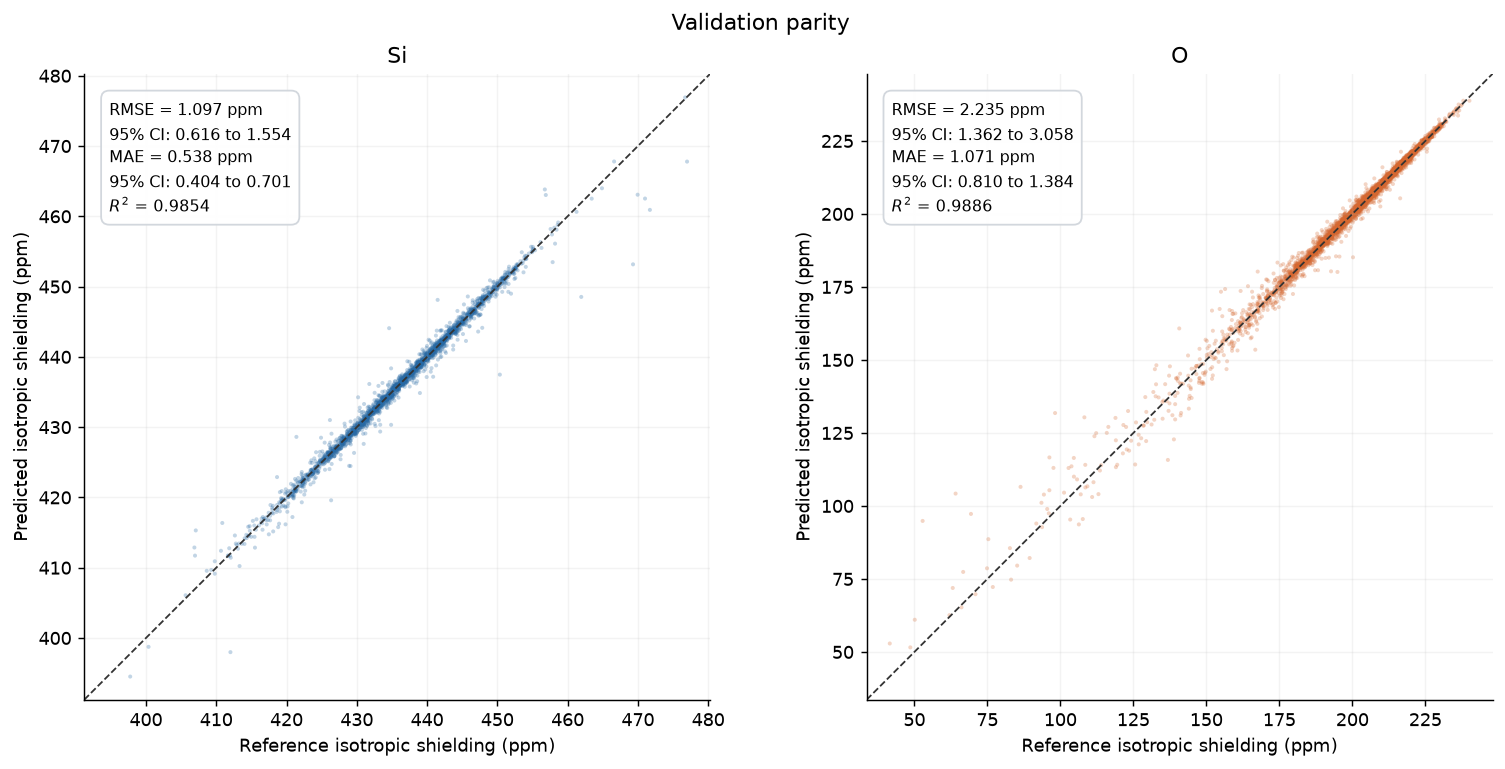

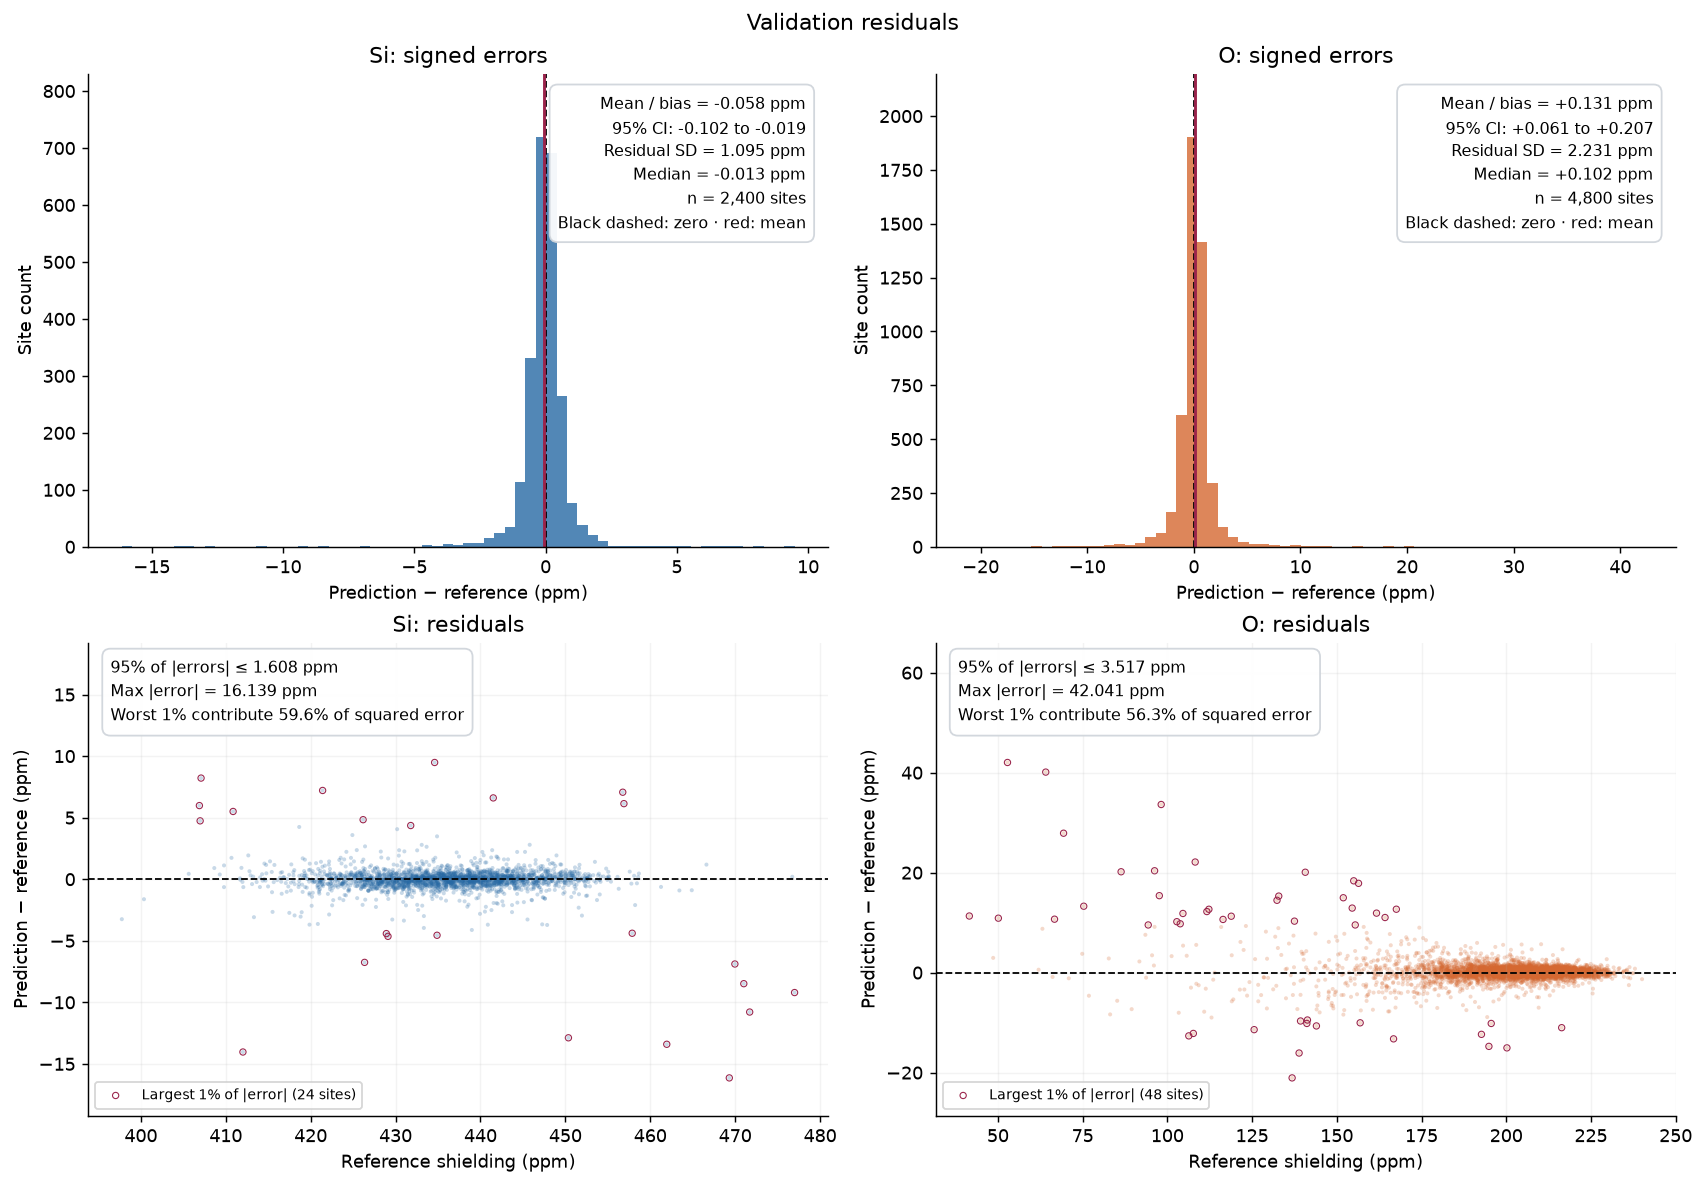

In [7]:
fig_parity, axes = plt.subplots(1, 2, figsize=(12, 5.8), layout='constrained')
for ax, element in zip(axes, ELEMENTS):
    group = validation_sites[validation_sites['element'].eq(element)]
    ref, pred = group['reference_ppm'].to_numpy(), group['prediction_ppm'].to_numpy()
    low, high = min(ref.min(), pred.min()), max(ref.max(), pred.max())
    margin = max(0.04 * (high - low), 0.1)
    limits = [low - margin, high + margin]
    ax.scatter(ref, pred, s=5, alpha=0.28, color=COLOURS[element], edgecolors='none', rasterized=True)
    ax.plot(limits, limits, '--', color='#333333', lw=1)
    ax.set(xlim=limits, ylim=limits, xlabel='Reference isotropic shielding (ppm)',
           ylabel='Predicted isotropic shielding (ppm)', title=element)
    ax.set_aspect('equal', adjustable='box')
    m = metrics.loc[('valid', element)]
    stats_box(ax, f'RMSE = {m.RMSE_ppm:.3f} ppm\n95% CI: {ci_text(element, "RMSE_ppm")}\n'
                 f'MAE = {m.MAE_ppm:.3f} ppm\n95% CI: {ci_text(element, "MAE_ppm")}\n'
                 f'$R^2$ = {m.R2:.4f}', x=0.04, ha='left')
    ax.grid(alpha=0.15)
fig_parity.suptitle('Validation parity')
plt.show()

fig_residuals, axes = plt.subplots(2, 2, figsize=(13, 9), layout='constrained')
for column, element in enumerate(ELEMENTS):
    group = validation_sites[validation_sites['element'].eq(element)]
    error = group['error_ppm'].to_numpy()
    m = metrics.loc[('valid', element)]
    ax = axes[0, column]
    ax.hist(error, bins=65, color=COLOURS[element], alpha=0.8)
    ax.axvline(0, color='black', linestyle='--', lw=1)
    ax.axvline(m.bias_ppm, color='#9a244b', lw=1.6)
    stats_box(ax, f'Mean / bias = {m.bias_ppm:+.3f} ppm\n'
                 f'95% CI: {ci_text(element, "bias_ppm", signed=True)}\n'
                 f'Residual SD = {error.std(ddof=0):.3f} ppm\n'
                 f'Median = {np.median(error):+.3f} ppm\n'
                 f'n = {len(error):,} sites\nBlack dashed: zero · red: mean', fontsize=9)
    ax.set(title=f'{element}: signed errors', xlabel='Prediction − reference (ppm)', ylabel='Site count')
    ax.set_ylim(0, ax.get_ylim()[1] * 1.1)

    ax = axes[1, column]
    tail_count = int(np.ceil(0.01 * len(error)))
    tail_positions = np.argsort(np.abs(error))[-tail_count:]
    tail_fraction = np.sum(error[tail_positions] ** 2) / np.sum(error ** 2)
    ax.scatter(group['reference_ppm'], error, s=5, alpha=0.25,
               color=COLOURS[element], edgecolors='none', rasterized=True)
    ax.scatter(group['reference_ppm'].to_numpy()[tail_positions], error[tail_positions], s=12,
               facecolors='none', edgecolors='#9a244b', linewidths=0.6,
               label=f'Largest 1% of |error| ({tail_count} sites)', rasterized=True)
    ax.axhline(0, color='black', linestyle='--', lw=1)
    stats_box(ax, f'95% of |errors| ≤ {m.p95_AE_ppm:.3f} ppm\n'
                 f'Max |error| = {m.max_AE_ppm:.3f} ppm\n'
                 f'Worst 1% contribute {100 * tail_fraction:.1f}% of squared error',
              x=0.03, y=0.97, ha='left', fontsize=9)
    ax.set(title=f'{element}: residuals', xlabel='Reference shielding (ppm)',
           ylabel='Prediction − reference (ppm)')
    lo, hi = error.min(), error.max()
    ax.set_ylim(lo - 0.12 * (hi - lo), hi + 0.38 * (hi - lo))
    ax.legend(loc='lower left', fontsize=8)
    ax.grid(alpha=0.15)
fig_residuals.suptitle('Validation residuals')
plt.show()


## 7. Structure errors


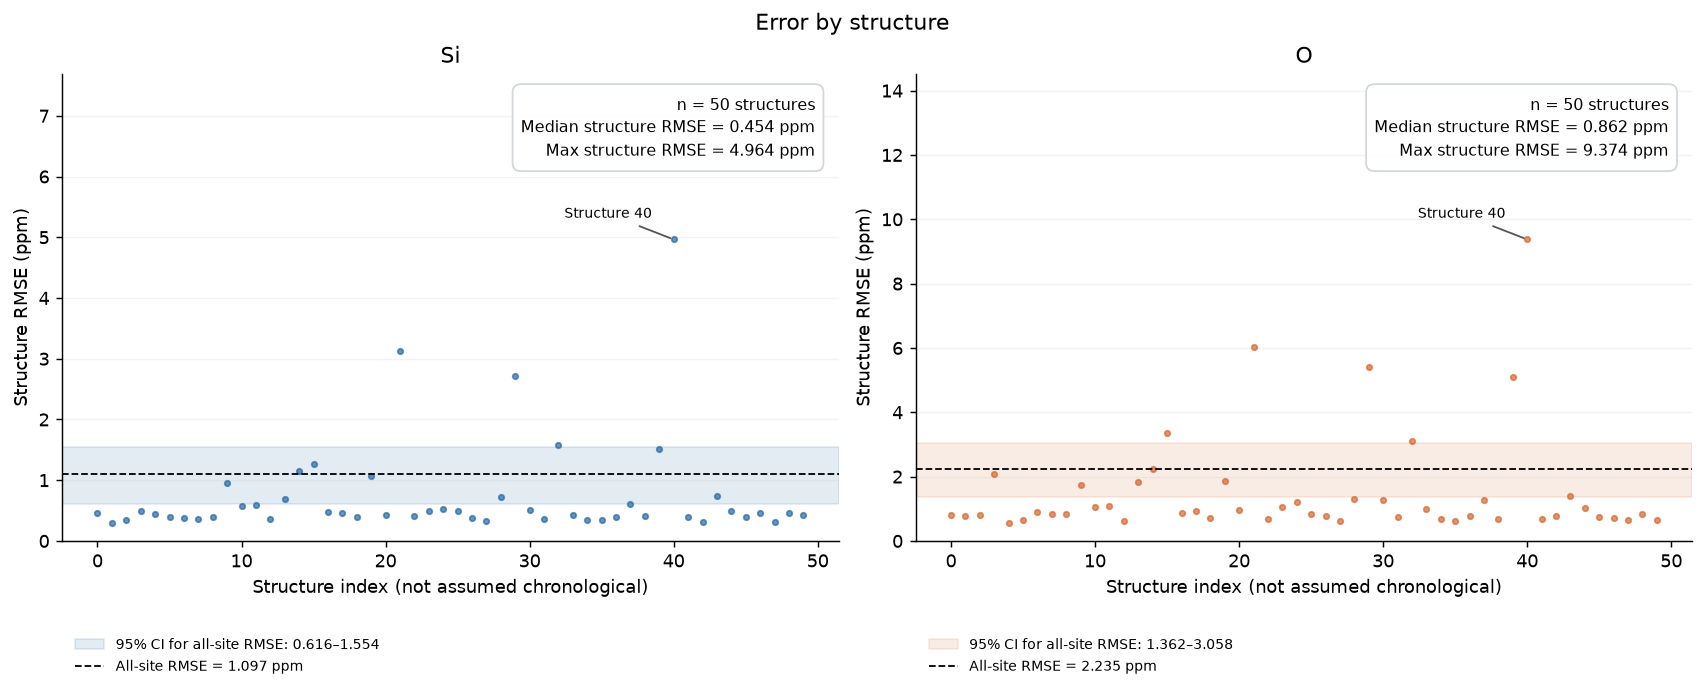

,element,structure_index,atom_index,reference_ppm,prediction_ppm,error_ppm
121086,Si,40,126,469.3066,453.1678,-16.1388
119506,Si,29,130,412.0194,397.9835,-14.0359
121088,Si,40,128,461.9409,448.5330,-13.4079
121073,Si,40,113,450.3575,437.4757,-12.8819
118328,Si,21,104,471.7069,460.9178,-10.7891
121055,O,40,95,52.8293,94.8707,42.0414
120977,O,40,17,64.1172,104.2347,40.1175
119464,O,29,88,98.1843,131.8180,33.6337
121032,O,40,72,69.3807,97.2719,27.8912
120844,O,39,28,108.2200,130.3454,22.1254


In [8]:
structure_rows = []
for (element, structure_index), group in validation_sites.groupby(['element', 'structure_index']):
    structure_rows.append({'element': element, 'structure_index': int(structure_index), 'sites': len(group),
                           **score(group['reference_ppm'], group['prediction_ppm'])})
structure_metrics = pd.DataFrame(structure_rows)
fig_structures, axes = plt.subplots(1, 2, figsize=(13, 5.2), layout='constrained')
for ax, element in zip(axes, ELEMENTS):
    group = structure_metrics[structure_metrics['element'].eq(element)]
    aggregate = metrics.loc[('valid', element), 'RMSE_ppm']
    ci = intervals.loc[(element, 'RMSE_ppm')]
    worst = group.loc[group['RMSE_ppm'].idxmax()]
    ax.axhspan(ci.lower_95_ppm, ci.upper_95_ppm, color=COLOURS[element], alpha=0.12,
               label=f'95% CI for all-site RMSE: {ci.lower_95_ppm:.3f}–{ci.upper_95_ppm:.3f}')
    ax.plot(group['structure_index'], group['RMSE_ppm'], 'o', ms=3, alpha=0.7, color=COLOURS[element])
    ax.axhline(aggregate, color='black', ls='--', lw=1,
               label=f'All-site RMSE = {aggregate:.3f} ppm')
    stats_box(ax, f'n = {len(group)} structures\nMedian structure RMSE = {group.RMSE_ppm.median():.3f} ppm\n'
                 f'Max structure RMSE = {worst.RMSE_ppm:.3f} ppm', fontsize=9)
    dx = -12 if worst.structure_index > len(structures['valid'])/2 else 12
    ax.annotate(f'Structure {int(worst.structure_index)}', (worst.structure_index, worst.RMSE_ppm),
                xytext=(dx, 12), textcoords='offset points', fontsize=8,
                ha='right' if dx < 0 else 'left', arrowprops={'arrowstyle':'-', 'color':'#555555'})
    ax.set(title=element, xlabel='Structure index (not assumed chronological)',
           ylabel='Structure RMSE (ppm)', ylim=(0, worst.RMSE_ppm * 1.55))
    ax.legend(loc='upper left', bbox_to_anchor=(0, -0.18), fontsize=8, frameon=False)
    ax.grid(axis='y', alpha=0.15)
fig_structures.suptitle('Error by structure')
plt.show()
worst_sites = pd.concat([validation_sites[validation_sites['element'].eq(el)].nlargest(5, 'absolute_error_ppm') for el in ELEMENTS])
display(worst_sites[['element','structure_index','atom_index','reference_ppm','prediction_ppm','error_ppm']].round(4))


## 8. Error by coordination


In [9]:
from ase.neighborlist import neighbor_list

COORDINATION_CUTOFF = 2.2  # Å; provisional geometric criterion, not a universal bond definition.
coordination_rows = []
for structure_index, atoms in enumerate(structures['valid']):
    centre, neighbour, distance = neighbor_list('ijd', atoms, COORDINATION_CUTOFF)
    unlike = (atoms.numbers[centre] != atoms.numbers[neighbour]) & (distance < COORDINATION_CUTOFF)
    counts = np.bincount(centre[unlike], minlength=len(atoms))
    coordination_rows.append(pd.DataFrame({
        'structure_index': structure_index, 'atom_index': np.arange(len(atoms)),
        'opposite_element_neighbours': counts,
    }))
coordination_sites = validation_sites.merge(pd.concat(coordination_rows, ignore_index=True),
                                      on=['structure_index', 'atom_index'], validate='one_to_one')
assert len(coordination_sites) == len(validation_sites)
coordination_sites['group'] = np.where(
    coordination_sites['opposite_element_neighbours'].eq(coordination_sites['element'].map({'Si': 4, 'O': 2})),
    'Common coordination', 'Other coordination')

# Resample full structures, including those with zero sites from a particular group.
coord_rng = np.random.default_rng(42)
n_structures = len(structures['valid'])
coord_draws = coord_rng.integers(0, n_structures, size=(2000, n_structures))
coordination_results = []
for element in ELEMENTS:
    element_sites = coordination_sites[coordination_sites['element'].eq(element)]
    for name in ['Common coordination', 'Other coordination']:
        group = element_sites[element_sites['group'].eq(name)]
        assert len(group) > 0, f'No {element} sites in {name} at this cutoff.'
        by_structure = group.groupby('structure_index')['error_ppm'].agg(
            n='size', squared_error=lambda x: float(np.square(x).sum()))
        by_structure = by_structure.reindex(np.arange(n_structures), fill_value=0)
        sample_counts = by_structure['n'].to_numpy()[coord_draws].sum(axis=1)
        sample_sse = by_structure['squared_error'].to_numpy()[coord_draws].sum(axis=1)
        nonempty = sample_counts > 0
        bootstrap_rmse = np.sqrt(sample_sse[nonempty] / sample_counts[nonempty])
        low, high = np.quantile(bootstrap_rmse, [0.025, 0.975])
        coordination_results.append({
            'element': element, 'group': name,
            'observed_neighbour_counts': ', '.join(map(str, sorted(group.opposite_element_neighbours.unique()))),
            'sites': len(group), 'percent_of_element_sites': 100 * len(group) / len(element_sites),
            'structures_containing_group': group.structure_index.nunique(),
            **score(group.reference_ppm, group.prediction_ppm),
            'RMSE_CI_lower_ppm': low, 'RMSE_CI_upper_ppm': high,
            'nonempty_bootstrap_resamples': int(nonempty.sum()),
        })
coordination_metrics = pd.DataFrame(coordination_results).set_index(['element', 'group'])
print(f'Validation-site coordination groups: unlike neighbours within {COORDINATION_CUTOFF:.1f} Å.')
display(coordination_metrics[['observed_neighbour_counts', 'sites', 'percent_of_element_sites',
                              'structures_containing_group', 'MAE_ppm', 'RMSE_ppm',
                              'RMSE_CI_lower_ppm', 'RMSE_CI_upper_ppm']].round(3))

# Keep the exact coordination categories visible rather than hiding them in the pooled groups.
coordination_detail = pd.DataFrame([
    {'element': element, 'neighbours': int(count), 'sites': len(group),
     'structures': group.structure_index.nunique(),
     'MAE_ppm': group.absolute_error_ppm.mean(),
     'RMSE_ppm': np.sqrt(np.mean(group.error_ppm ** 2))}
    for (element, count), group in coordination_sites.groupby(['element', 'opposite_element_neighbours'])
]).set_index(['element', 'neighbours'])


Validation-site coordination groups: unlike neighbours within 2.2 Å.


observed_neighbour_counts  sites  percent_of_element_sites  structures_containing_group  MAE_ppm  RMSE_ppm  RMSE_CI_lower_ppm  \
element group                                                                                                                                               
Si      Common coordination                         4   2386                    99.417                           50    0.500     0.884              0.601   
        Other coordination                          5     14                     0.583                            5    6.915     8.549              0.846   
O       Common coordination                         2   4762                    99.208                           50    1.018     1.944              1.240   
        Other coordination                       1, 3     38                     0.792                           13    7.695    12.553              5.880   

                             RMSE_CI_upper_ppm  
element group                                   
Si      Common coordination              1.136  
        Other coordination               9.628  
O       Common coordination              2.578  
        Other coordination              15.551

Exact coordination categories (small groups require caution):


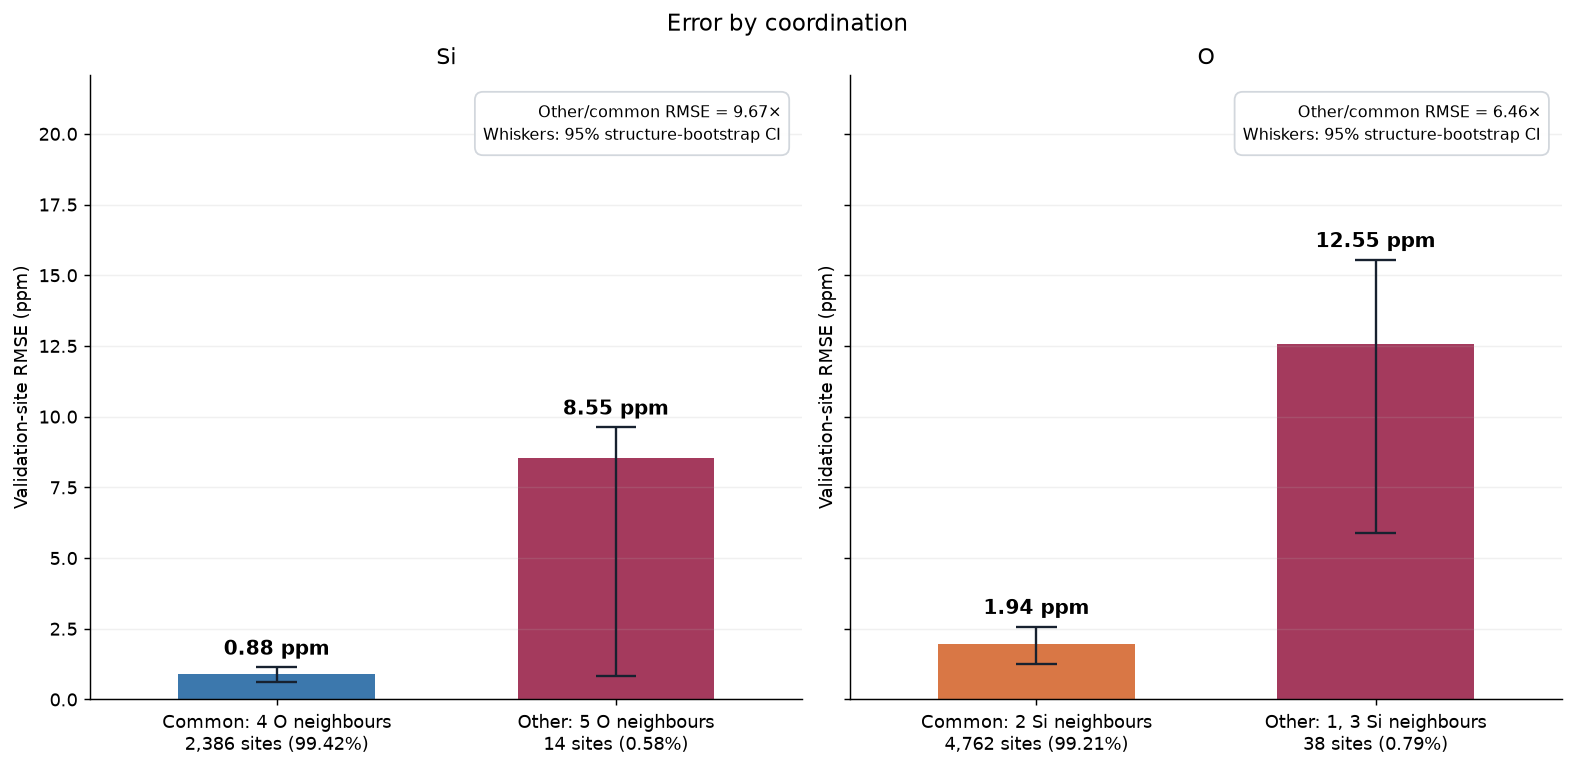

sites  structures  MAE_ppm  RMSE_ppm
element neighbours                                      
O       1              12          10   15.347    20.868
        2            4762          50    1.018     1.944
        3              26          13    4.163     5.416
Si      4            2386          50    0.500     0.884
        5              14           5    6.915     8.549

In [10]:
fig_coordination, axes = plt.subplots(1, 2, figsize=(12, 5.8), sharey=True, layout='constrained')
max_interval = coordination_metrics.RMSE_CI_upper_ppm.max()
for ax, element in zip(axes, ELEMENTS):
    table = coordination_metrics.loc[element].loc[['Common coordination', 'Other coordination']]
    values = table.RMSE_ppm.to_numpy()
    low, high = table.RMSE_CI_lower_ppm.to_numpy(), table.RMSE_CI_upper_ppm.to_numpy()
    positions = np.arange(2)
    ax.bar(positions, values, width=0.58, color=[COLOURS[element], '#9a244b'], alpha=0.9)
    # Draw percentile interval bounds directly (no assumption that they contain the point estimate).
    ax.vlines(positions, low, high, color='#17212f', linewidth=1.3)
    ax.hlines(low, positions-0.06, positions+0.06, color='#17212f', linewidth=1.3)
    ax.hlines(high, positions-0.06, positions+0.06, color='#17212f', linewidth=1.3)
    for x, value, upper in zip(positions, values, high):
        ax.annotate(f'{value:.2f} ppm', (x, max(value, upper)), xytext=(0, 7),
                    textcoords='offset points', ha='center', fontsize=11, fontweight='bold')
    neighbour = 'O' if element == 'Si' else 'Si'
    tick_labels = []
    for (_, row), kind in zip(table.iterrows(), ['Common', 'Other']):
        tick_labels.append(f'{kind}: {row.observed_neighbour_counts} {neighbour} neighbours\n'
                           f'{int(row.sites):,} sites ({row.percent_of_element_sites:.2f}%)')
    ax.set_xticks(positions, tick_labels, fontsize=10)
    ratio = values[1] / values[0]
    stats_box(ax, f'Other/common RMSE = {ratio:.2f}×\nWhiskers: 95% structure-bootstrap CI', fontsize=9)
    ax.set(title=element, ylabel='Validation-site RMSE (ppm)',
           ylim=(0, max_interval * 1.42), xlim=(-0.55, 1.55))
    ax.grid(axis='y', alpha=0.18)
fig_coordination.suptitle('Error by coordination',
                         fontsize=13)
plt.show()
print('Exact coordination categories (small groups require caution):')
display(coordination_detail.round(3))


## 9. Results


In [11]:
lines = [f'**Best checkpoint: epoch {best_epoch} of {last_epoch}.** ',
         f"Validation evaluation: {len(structures['valid'])} structures and {len(validation_sites):,} atomic sites.", '']
for element in ELEMENTS:
    m = metrics.loc[('valid', element)]
    interval = intervals.loc[(element, 'RMSE_ppm')]
    lines.append(f"- **{element}:** MAE **{m.MAE_ppm:.3f} ppm**, RMSE **{m.RMSE_ppm:.3f} ppm**, "
                 f"bias {m.bias_ppm:+.3f} ppm, $R^2={m.R2:.4f}$. "
                 f"Structure-bootstrap RMSE interval: {interval.lower_95_ppm:.3f}–{interval.upper_95_ppm:.3f} ppm. "
                 f"RMSE is {m.RMSE_reduction_vs_baseline_pct:.1f}% below the elemental-mean baseline "
                 f"on the validation structures.")
lines += ['', 'These validation structures selected the checkpoint. Use these results for development, not as an independent final assessment. No test dataset was loaded.']
display(Markdown('\n'.join(lines)))

manifest = {
    'evaluation_utc': datetime.now(timezone.utc).isoformat(),
    'run': RUN_NAME, 'best_epoch_1based': best_epoch, 'last_epoch_1based': last_epoch,
    'target': 'MS_Iso_QM = trace(ms)/3; absolute isotropic shielding', 'units': 'ppm',
    'error_sign': 'prediction minus reference', 'reference': 'CASTEP/PBE labels in supplied XYZ files',
    'model_sha256': model_hash, 'best_checkpoint_sha256': sha256(RUN / 'checkpoints/best.ckpt'),
    'config_sha256': sha256(RUN / 'train-config.yaml'),
    'helper_sha256': sha256(PROJECT / 'nmr_helpers/extract_ms_isotropy.py'),
    'data_sha256': data_hashes, 'versions': versions, 'python': platform.python_version(),
    'device': 'cpu', 'dtype': 'float32 predictions; float64 metrics', 'torch_threads': THREADS,
    'site_counts': audit['sites'].to_dict(), 'structure_counts': audit['structures'].to_dict(),
    'bootstrap': {'unit': 'structure', 'resamples': 2000, 'seed': 42,
                  'limitation': 'Assumes independent structures; trajectory dependence not assessed.'},
    'coordination_diagnostic': {'cutoff_A': COORDINATION_CUTOFF, 'periodic': True,
        'groups': 'Si: 4 versus other O neighbours; O: 2 versus other Si neighbours',
        'split': 'valid', 'bootstrap_resamples': 2000, 'seed': 42},
    'corrections_applied': False, 'outliers_removed': False,
}
print(json.dumps(manifest, indent=2))
print('Tables remain available as metrics, sites, structure_metrics, intervals and audit.')


{
  "evaluation_utc": "2026-10-16T08:49:40.628787+00:00",
  "run": "TensorNequIP-NMR-9065266",
  "best_epoch_1based": 188,
  "last_epoch_1based": 300,
  "target": "MS_Iso_QM = trace(ms)/3; absolute isotropic shielding",
  "units": "ppm",
  "error_sign": "prediction minus reference",
  "reference": "CASTEP/PBE labels in supplied XYZ files",
  "model_sha256": "f2159b2fe9bd80147c46b55413c233cd616d825c976e75bf80de345f4104b32a",
  "best_checkpoint_sha256": "4d93d7073e527b408e9450efbb289901e87670b2bfd9d2b183cdcb1bf31e490c",
  "config_sha256": "7e510894939e38f50da45b5fb23dadcf0932b70a627f3661bda73e15d798a209",
  "helper_sha256": "e22e6ebab1fbb34869c0ba73ffceb2542e96eae9e66f927dd70b653376d8d78f",
  "data_sha256": {
    "train": "77de1ed9983781e906c35aa63d4f134a0777c6e38a933791c6db866f8b9c6fda",
    "valid": "e73ce6065ce6729d6549d5b30a4129634aaec84e3a2429c044d31d81020a4d11"
  },
  "versions": {
    "graph-pes": "1.0.2",
    "torch": "2.6.0",
    "e3nn": "0.4.4",
    "ase": "3.29.0",
    "numpy"

**Best checkpoint: epoch 188 of 300.** 
Validation evaluation: 50 structures and 7,200 atomic sites.

- **Si:** MAE **0.538 ppm**, RMSE **1.097 ppm**, bias -0.058 ppm, $R^2=0.9854$. Structure-bootstrap RMSE interval: 0.616–1.554 ppm. RMSE is 87.9% below the elemental-mean baseline on the validation structures.
- **O:** MAE **1.071 ppm**, RMSE **2.235 ppm**, bias +0.131 ppm, $R^2=0.9886$. Structure-bootstrap RMSE interval: 1.362–3.058 ppm. RMSE is 89.3% below the elemental-mean baseline on the validation structures.

These validation structures selected the checkpoint. Use these results for development, not as an independent final assessment. No test dataset was loaded.

**Method notes.** Errors are unweighted; signed residuals are prediction minus reference. 95% intervals resample whole structures and exclude seed variability and checkpoint-selection uncertainty. The structure-plot band describes aggregate RMSE, not individual structures. Coordination counts use periodic Si–O distances below 2.2 Å; these are descriptive groups. Validation selected the checkpoints; this is not an independent test.
